# Chunked prefill: performance vs energy, A100 vs H100

Each panel: **energy per token** (y) against one performance metric (x), for one model and dataset.

- **Colour** = chunk size (the per-step token budget): light blue = small chunks (256) → dark blue = large (4096); **orange** = no chunking.
- **Filled** markers = H100 (Nat), **hollow** = A100 (Abraar). Each point is the mean of 3 seeds (seed-to-seed spread is in the table at the end; set `SHOW_SEED_RANGE = True` to draw it).
- **Lines** = Pareto frontier per GPU (no other chunk size on that GPU is better on both latency and energy). Solid = H100, dashed = A100. None on the throughput column (dotted line = the request rate each GPU ran at).
- Small grey text (first column): how much the chunk sizes differ in energy per token vs. how much the 3 seeds differ. Where seeds differ more, the energy ordering of chunk sizes is not reliable.
- Latency axes are log-scale where a panel spans 3x or more. No SLOs are drawn yet.
- Caution: P99 TBT can hide rare long stalls (e.g. no chunking on Arxiv): stalls under 1% of token gaps don't move the 99th percentile.

Data: `benchmarks/H_100/results/` (Nat) and `benchmarks/A_100/results/` (Abraar), both made by `H_100/scripts/summarize.py`. Same prompts, rate = 0.5 x each GPU's own burst throughput, vLLM 0.34.0. Run from this folder; figures go to `figures/`.

In [1]:
import csv, json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import LogLocator, FuncFormatter, NullFormatter

# Paths are relative to this notebook (benchmarks/analysis/), so it runs on any checkout of the repo.
SOURCES = {  # gpu label -> (summarized results root, folder name used inside it)
    "H100": ("../H_100/results", "H100-80GB-HBM3"),
    "A100": ("../A_100/results", "A100-80GB-PCIe"),
}
OUT_DIR = "figures"
os.makedirs(OUT_DIR, exist_ok=True)

MODELS = {"Qwen2.5-3B-Instruct": "3B", "Qwen2.5-14B-Instruct": "14B"}
DATASETS = {"sharegpt": "ShareGPT", "arxiv": "Arxiv"}
ROWS = [("Qwen2.5-3B-Instruct", "sharegpt"), ("Qwen2.5-14B-Instruct", "sharegpt"),
        ("Qwen2.5-3B-Instruct", "arxiv"), ("Qwen2.5-14B-Instruct", "arxiv")]
CHUNKS = ["256", "512", "1024", "2048", "4096", "none"]

# Chunk size is ordered: one blue ramp, light -> dark (validated: monotone, visible steps, light end >= 2:1).
# "none" (prompts never split) is a different kind of setting, so it gets a separate hue.
CHUNK_COLOR = {"256": "#84b9f3", "512": "#519ced", "1024": "#257de0", "2048": "#1b64be",
               "4096": "#0f4a96", "none": "#f47230"}
CHUNK_LABEL = {c: ("no chunking" if c == "none" else f"chunk {c}") for c in CHUNKS}
INK, INK2, GRID, AXIS = "#191919", "#666666", "#e7e7e7", "#c2c2c2"


In [2]:
def load_runs():
    """One row per run (2 GPUs x 2 models x 2 datasets x 6 chunks x 3 seeds = 144), incl. P99 TBT from metrics.json."""
    rows = []
    for gpu, (root, folder) in SOURCES.items():
        for r in csv.DictReader(open(f"{root}/sweep50/runs.csv")):
            m = json.load(open(f"{root}/sweep50/{folder}/{r['model']}/chunk-{r['chunk']}/{r['dataset']}/seed{r['seed']}/metrics.json"))
            lat = m["latency_ms"]
            rows.append(dict(
                gpu=gpu, model=r["model"], dataset=r["dataset"], chunk=r["chunk"], seed=int(r["seed"]),
                completed=int(r["completed"]), failed=int(r["failed"]),
                request_rate=float(r["request_rate"]), request_throughput_rps=float(r["request_throughput_rps"]),
                p99_ttft_ms=lat["p99_ttft_ms"], median_ttft_ms=lat["median_ttft_ms"],
                p99_tbt_ms=lat["p99_itl_ms"], median_tbt_ms=lat["median_itl_ms"],
                avg_power_w=float(r["avg_power_w"]), total_energy_j=float(r["total_energy_j"]),
                energy_per_request_j=float(r["energy_per_request_j"]), energy_per_token_j=float(r["energy_per_token_j"]),
            ))
    return pd.DataFrame(rows)

runs = load_runs()
assert len(runs) == 144, len(runs)
assert (runs.completed == 250).all() and (runs.failed == 0).all()
assert runs.groupby(["gpu", "model", "dataset", "chunk"]).size().eq(3).all()   # 3 seeds everywhere

METRICS = ["request_rate", "p99_ttft_ms", "median_ttft_ms", "p99_tbt_ms", "median_tbt_ms", "request_throughput_rps",
           "avg_power_w", "total_energy_j", "energy_per_request_j", "energy_per_token_j"]
g = runs.groupby(["gpu", "model", "dataset", "chunk"])[METRICS]
mean, lo, hi = g.mean(), g.min(), g.max()
print(f"{len(runs)} runs, {len(mean)} points (mean of 3 seeds)")


144 runs, 48 points (mean of 3 seeds)


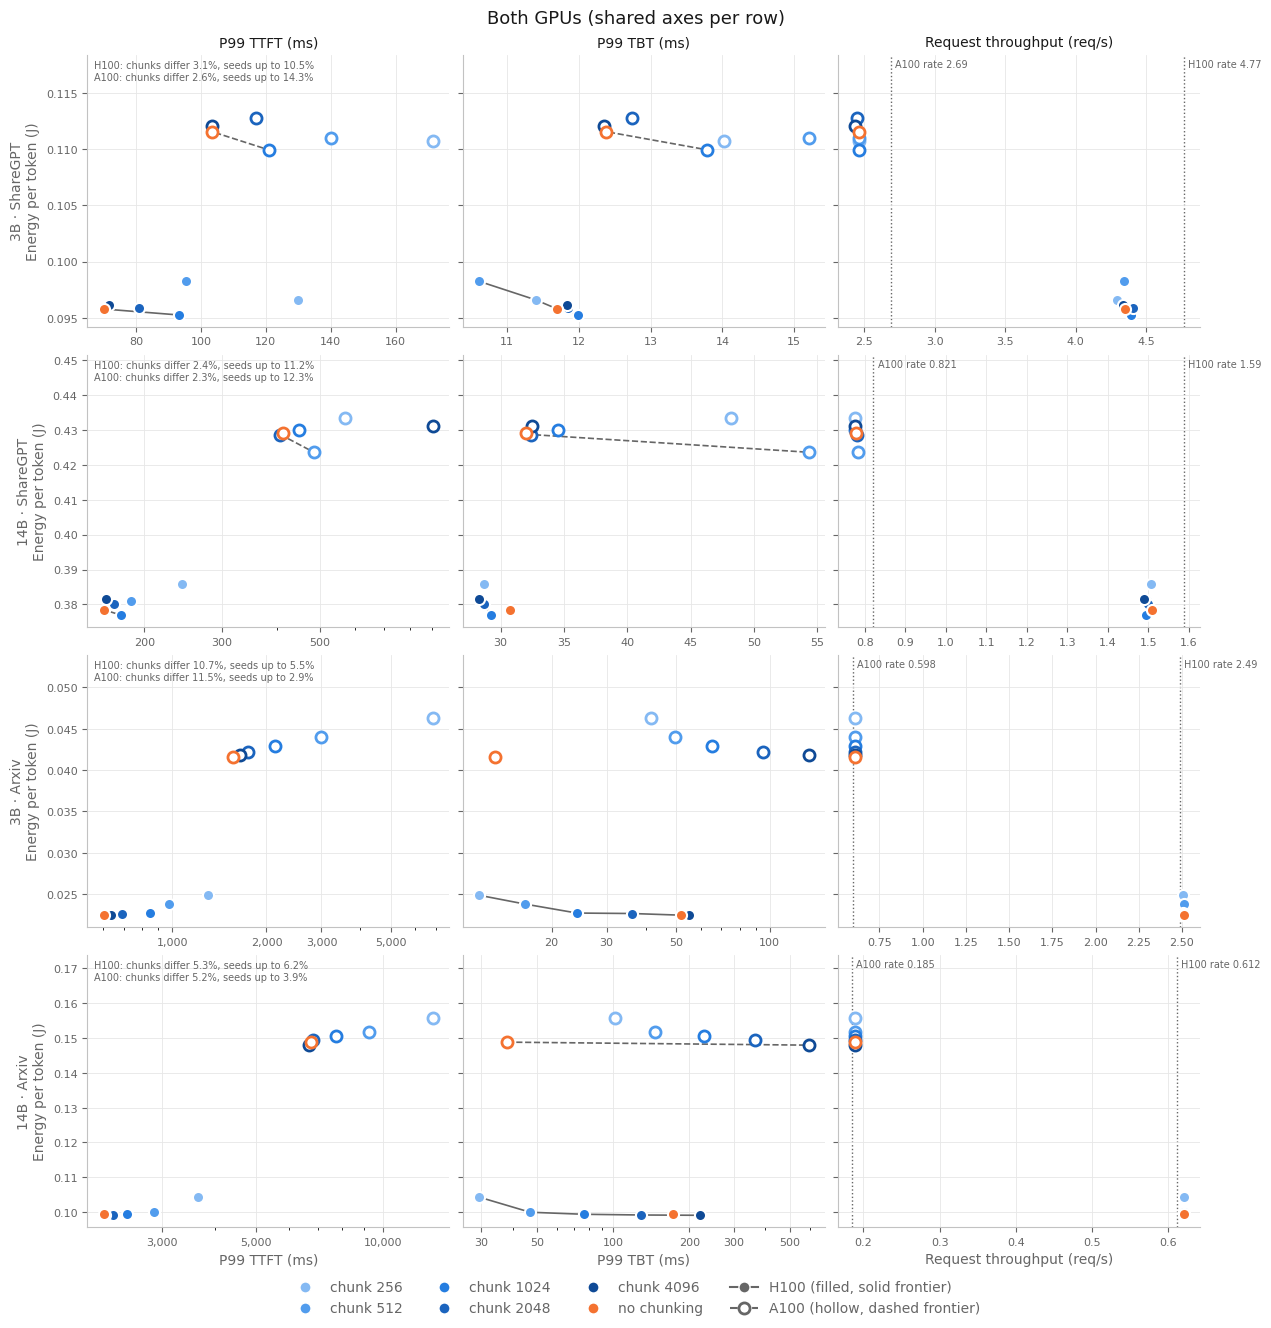

In [3]:
def pareto(xs, ys):
    """Indices of points not dominated by any other (lower x and lower y are better)."""
    pts = list(zip(xs, ys)); keep = []
    for i, (x, y) in enumerate(pts):
        dominated = any(a <= x and b <= y and (a, b) != (x, y) for a, b in pts)
        if not dominated:
            keep.append(i)
    return sorted(keep, key=lambda i: pts[i][0])

# x-axis per column: (metric, label, log scale allowed?, Pareto frontier?)
COLUMNS = [
    ("p99_ttft_ms", "P99 TTFT (ms)", True, True),
    ("p99_tbt_ms", "P99 TBT (ms)", True, True),
    ("request_throughput_rps", "Request throughput (req/s)", False, False),  # proposal's 3rd column; fixed by the request rate
]

GPU_STYLE = {"H100": (True, "-"), "A100": (False, "--")}   # (filled marker?, frontier line style)
SHOW_SEED_RANGE = False   # True: thin bars spanning the 3 seeds (min-max)

def grid(columns=COLUMNS, gpus=("H100", "A100"), y="energy_per_token_j", ylabel="Energy per token (J)", fname="grid", title=None):
    fig, axes = plt.subplots(len(ROWS), len(columns), figsize=(4.2 * len(columns), 3.3 * len(ROWS)),
                             sharey="row", constrained_layout=True)
    for r, (model, ds) in enumerate(ROWS):
        for c, (x, xlabel, logx, frontier) in enumerate(columns):
            ax = axes[r, c]
            allx = [mean.loc[(gpu, model, ds, ch), x] for gpu in gpus for ch in CHUNKS]
            logx = logx and max(allx) / min(allx) >= 3   # log only where the panel spans >= 3x
            for gpu in gpus:
                filled, ls = GPU_STYLE[gpu]
                xs, ys = [], []
                for ch in CHUNKS:
                    k = (gpu, model, ds, ch)
                    mx, my = mean.loc[k, x], mean.loc[k, y]
                    xs.append(mx); ys.append(my)
                    col = CHUNK_COLOR[ch]
                    if SHOW_SEED_RANGE:
                        ax.errorbar(mx, my, xerr=[[mx - lo.loc[k, x]], [hi.loc[k, x] - mx]],
                                    yerr=[[my - lo.loc[k, y]], [hi.loc[k, y] - my]],
                                    fmt="none", ecolor=col, elinewidth=1, alpha=0.6, zorder=2)
                    ax.plot(mx, my, "o", ms=8, mfc=col if filled else "white", mec=col if not filled else "white",
                            mew=2 if not filled else 1.5, zorder=3)
                if frontier:
                    f = pareto(xs, ys)
                    ax.plot([xs[i] for i in f], [ys[i] for i in f], ls, color=INK2, lw=1.2, zorder=1)
                if x == "request_throughput_rps":   # mark the offered request rate this GPU ran at
                    rate = mean.loc[(gpu, model, ds, "2048"), "request_rate"]
                    ax.axvline(rate, color=INK2, lw=1, ls=":", zorder=0)
                    ax.annotate(f"{gpu} rate {rate:.3g}", (rate, 1), xycoords=("data", "axes fraction"),
                                xytext=(3, -3), textcoords="offset points", va="top", fontsize=7, color=INK2)
            if x == "request_throughput_rps" and len(gpus) == 1:
                ax.set_xlim(rate * 0.9, rate * 1.1)   # +-10%: real differences are < 3%, don't magnify them
            if c == 0:   # how big are chunk-size differences compared with seed-to-seed differences?
                lines = []
                for gpu in gpus:
                    m_ = [mean.loc[(gpu, model, ds, ch), y] for ch in CHUNKS]
                    seed = max(hi.loc[(gpu, model, ds, ch), y] / lo.loc[(gpu, model, ds, ch), y] - 1 for ch in CHUNKS)
                    lines.append(f"{gpu}: chunks differ {max(m_) / min(m_) - 1:.1%}, seeds up to {seed:.1%}")
                ally = [mean.loc[(gpu, model, ds, ch), y] for gpu in gpus for ch in CHUNKS]
                rng = max(ally) - min(ally)
                ax.set_ylim(min(ally) - 0.06 * rng, max(ally) + (0.12 + 0.1 * len(gpus)) * rng)   # headroom for the note (row shares y)
                ax.text(0.02, 0.98, "\n".join(lines), transform=ax.transAxes, ha="left", va="top",
                        fontsize=7, color=INK2)
            if logx:
                ax.set_xscale("log")
                # plain-number ticks at 1-2-3-5 steps (e.g. 30, 50, 100, 200 ms), no minor labels
                ax.xaxis.set_major_locator(LogLocator(base=10, subs=(1.0, 2.0, 3.0, 5.0)))
                ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
                ax.xaxis.set_minor_formatter(NullFormatter())
            ax.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True)
            for s in ("top", "right"):
                ax.spines[s].set_visible(False)
            for s in ("left", "bottom"):
                ax.spines[s].set_color(AXIS)
            ax.tick_params(colors=INK2, labelsize=8)
            if r == len(ROWS) - 1:
                ax.set_xlabel(xlabel, color=INK2)
            if c == 0:
                ax.set_ylabel(f"{MODELS[model]} · {DATASETS[ds]}\n{ylabel}", color=INK2)
            if r == 0:
                ax.set_title(xlabel, color=INK, fontsize=10)
    handles = [Line2D([], [], marker="o", ls="", ms=8, mfc=CHUNK_COLOR[ch], mec="white", label=CHUNK_LABEL[ch]) for ch in CHUNKS]
    gpu_handle = {"H100": Line2D([], [], marker="o", ls="-", color=INK2, ms=8, mfc=INK2, mec="white", label="H100 (filled, solid frontier)"),
                  "A100": Line2D([], [], marker="o", ls="--", color=INK2, ms=8, mfc="white", mec=INK2, mew=2, label="A100 (hollow, dashed frontier)")}
    handles += [gpu_handle[gpu] for gpu in gpus]
    fig.legend(handles=handles, loc="outside lower center", ncol=4, frameon=False, labelcolor=INK2)
    if title:
        fig.suptitle(title, color=INK, fontsize=13)
    fig.savefig(f"{OUT_DIR}/{fname}.png", dpi=150); fig.savefig(f"{OUT_DIR}/{fname}.pdf")
    return fig

fig = grid(title="Both GPUs (shared axes per row)")
plt.show()


## One figure per GPU
Same layout, colours and markers, but each GPU gets its own axes, so the differences between its chunk sizes are not squeezed by the gap between GPUs. **Axis ranges differ between the two figures: compare GPUs with the combined figure above, not by eye across these two.**

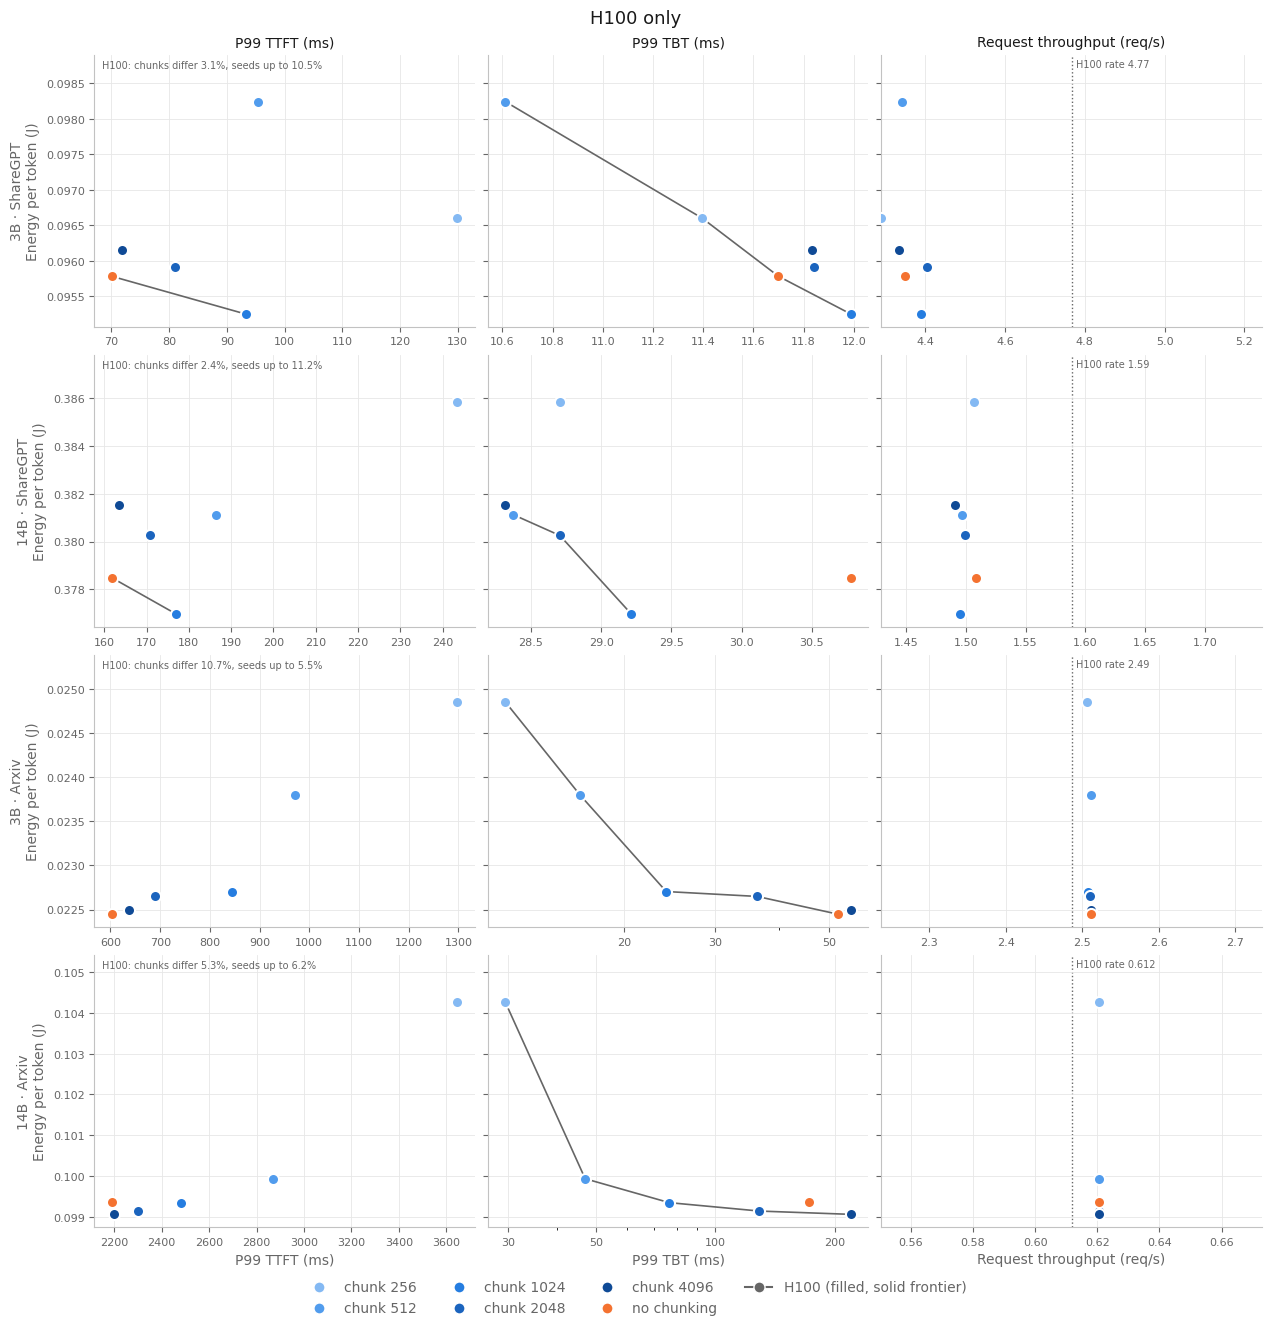

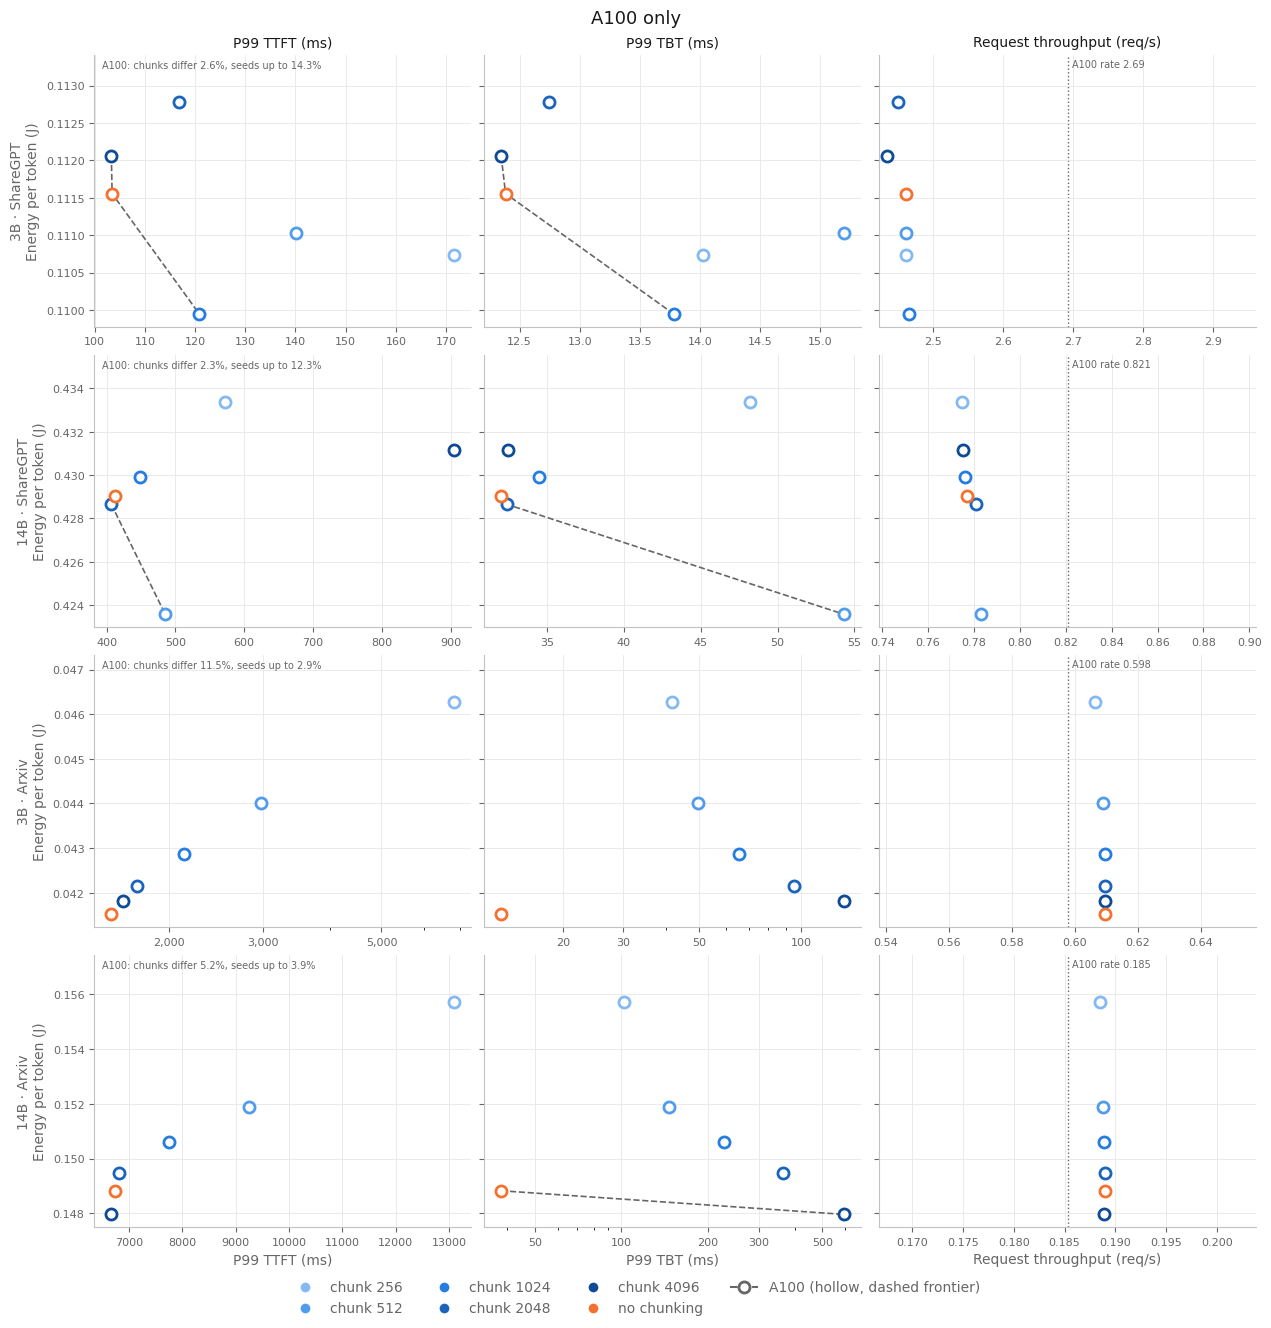

In [4]:
for gpu in ("H100", "A100"):
    fig = grid(gpus=(gpu,), fname=f"grid_{gpu}", title=f"{gpu} only")
    plt.show()


**Why measured throughput sits left of the dotted rate line on ShareGPT:** the benchmark divides completed requests by the time until the *last* request finishes, which includes the drain after the final arrival; ShareGPT's long answers make that tail long (~8% here). It is not falling behind: every run kept up (served/offered >= 0.994).

**Why the throughput column is (nearly) flat:** every chunk size of a GPU received requests at the same fixed rate, and none fell behind, so each finished requests as fast as they arrived. Measured throughput therefore equals the rate we chose (within ~3%); chunk size shows up in latency and energy instead. To try another x-axis, edit `COLUMNS` (e.g. `("median_ttft_ms", "Median TTFT (ms)", True, False)` or `("avg_power_w", "Average GPU power (W)", False, False)`).

In [5]:
# Summary table (mean of 3 seeds): the proposal's auxiliary energy metrics, with the plotted ones.
table = mean.copy()
table["energy_per_token_seed_spread"] = hi["energy_per_token_j"] / lo["energy_per_token_j"] - 1   # (max/min over 3 seeds) - 1
table = table.reset_index()
table["model"] = table["model"].map(MODELS); table["dataset"] = table["dataset"].map(DATASETS)
table["chunk"] = pd.Categorical(table["chunk"], CHUNKS, ordered=True)
table = table.sort_values(["dataset", "model", "gpu", "chunk"]).set_index(["dataset", "model", "gpu", "chunk"])
cols = ["energy_per_token_j", "energy_per_request_j", "total_energy_j", "avg_power_w",
        "p99_ttft_ms", "median_ttft_ms", "p99_tbt_ms", "request_throughput_rps", "energy_per_token_seed_spread"]
table = table[cols]
table.to_csv(f"{OUT_DIR}/summary_table.csv")
table.style.format({"energy_per_token_j": "{:.4f}", "energy_per_request_j": "{:.1f}", "total_energy_j": "{:,.0f}",
                    "avg_power_w": "{:.0f}", "p99_ttft_ms": "{:,.0f}", "median_ttft_ms": "{:,.0f}",
                    "p99_tbt_ms": "{:.1f}", "request_throughput_rps": "{:.3f}",
                    "energy_per_token_seed_spread": "{:.1%}"})
